# Backtesting Trading Strategies with vectorbt: Cointegration Pairs Trading with an ML Filter, ML Sector Rotation and Beta Hedging

Most backtests look better than the strategy will ever do live, because they peek at the future, try many variants and ignore costs. This notebook builds three systematic equity strategies under rules designed to avoid those traps, and measures what machine learning and hedging really add once costs are paid.

**What it does.** It builds and backtests three systematic strategies on U.S. equities with realistic costs and strict walk-forward rules, using `vectorbt` for the portfolio simulation.

1. **Statistical arbitrage.** Every six months, cointegrated pairs are selected within seven sectors (Engle–Granger test, half-life filter) and traded on z-score signals for the next six months. A **LightGBM filter**, trained only on earlier trades, decides which signals to take.
2. **ML sector rotation.** A LightGBM model ranks the nine SPDR sector ETFs on next-month relative returns, and the top three are held, against momentum and equal weight.
3. **Hedging.** The market beta left in each strategy is removed with SPY, using a rolling-OLS or a Kalman-filter hedge ratio.

**Data.** Yahoo Finance (daily prices since 2010 for about 50 large U.S. stocks in seven sectors, the nine sector ETFs and SPY) and FRED (VIX, term spread).

**Methods.** Engle–Granger cointegration and Ornstein–Uhlenbeck half-lives (`statsmodels`), z-score entry and exit rules, a LightGBM trade classifier and return ranker with walk-forward training, and `vectorbt` `Portfolio.from_orders` with target-percent sizing, cash sharing and fees.

Hedges use rolling and Kalman betas, and results are measured by Sharpe ratio, drawdown, hit rate and trade statistics.

**Key output.** Equity curves, performance tables, the value added by the ML filter and by hedging, and trade-level diagnostics.

## 1. Backtesting without fooling yourself

Most published backtests overstate live performance. Bailey and López de Prado list the main reasons:
- look-ahead bias;
- selection bias from trying many variants;
- survivorship bias;
- unrealistic costs.

The rules here are designed to keep those small:
- **Walk-forward everything:** pairs are chosen on the previous 12 months only, and ML models are trained only on trades that closed before the current window opened.
- **Costs:** 5 bp per side on every trade, applied by `vectorbt` as fees on traded value, plus a 1% annual borrow cost on short positions for the pairs book.
- **Execution:** signals are computed at the close and executed at the next close.
- **Survivorship:** the stock universe is today's large caps, which flatters long-only results. Market-neutral pairs are much less affected, but not immune: pairs whose members later failed never appear.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import itertools
import lightgbm as lgb
import vectorbt as vbt
import yfinance as yf
from statsmodels.tsa.stattools import coint

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 67
warnings.filterwarnings("ignore", message=".*keyword-only.*")
rng = np.random.default_rng(SEED)
SECTORS = {
    "banks": ["JPM", "BAC", "C", "WFC", "GS", "MS", "USB", "PNC"],
    "energy": ["XOM", "CVX", "COP", "EOG", "SLB", "OXY", "PSX", "VLO"],
    "utilities": ["DUK", "SO", "D", "AEP", "EXC", "XEL", "ED", "PEG"],
    "staples": ["KO", "PEP", "PG", "CL", "KMB", "GIS", "MDLZ", "HSY"],
    "tech": ["MSFT", "AAPL", "ORCL", "CSCO", "IBM", "INTC", "TXN", "QCOM"],
    "industrials": ["CAT", "DE", "HON", "MMM", "UNP", "CSX", "NSC", "EMR"],
    "retail": ["WMT", "TGT", "COST", "HD"],
}
STOCKS = [t for v in SECTORS.values() for t in v]
ETFS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
START = "2010-01-01"
# formation and trading windows (days)
FORM, TRADE = 252, 126
N_PAIRS, ENTRY_Z, EXIT_Z, STOP_Z = 10, 2.0, 0.0, 4.0
FEE = 0.0005  # 5 bp per side
BORROW = 0.01  # annual cost of shorting
# gross exposure per leg per open pair (fraction of capital)
PAIR_WEIGHT = 0.10

print(
    f"vectorbt {vbt.__version__} · lightgbm {lgb.__version__} · yfinance"
    f" {yf.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

vectorbt 1.2.0 · lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-10-21


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

In [3]:
def fetch_prices():
    px = yf.download(
        STOCKS + ETFS + ["SPY"], start=START, auto_adjust=True, progress=False
    )["Close"]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name = "date"
    return px.reset_index()


PX = cached("prices", fetch_prices).set_index("date").sort_index()
PX = PX[PX.index < pd.Timestamp.today().normalize()].ffill(limit=5)
STOCKS = [s for s in STOCKS if PX[s].notna().mean() > 0.95]
LP = np.log(PX)
vix = fred.get_series("VIXCLS").reindex(PX.index).ffill()
term = fred.get_series("T10Y3M").reindex(PX.index).ffill()
print(
    f"{len(PX):,} days · {PX.index[0]:%Y-%m-%d} → {PX.index[-1]:%Y-%m-%d} ·"
    f" {len(STOCKS)} stocks, {len(ETFS)} sector ETFs, SPY"
)

4,225 days · 2010-01-04 → 2026-10-20 · 51 stocks, 9 sector ETFs, SPY


## 3. Strategy 1: cointegration pairs trading

**Formation (every 126 trading days, on the previous 252):** for every pair within a sector:
- regress log P_A on log P_B to get the hedge ratio β;
- run the Engle–Granger test on the residual spread s = log P_A − β·log P_B;
- estimate its half-life from an AR(1) on Δs.

Pairs are kept if p < 0.05 and the half-life is between 5 and 60 days. The 10 with the lowest p-values are traded.

**Trading (the next 126 days):**
- the z-score uses the formation-window mean and standard deviation of s;
- enter when |z| > 2: short the spread when z > 2, long it when z < −2;
- exit when z crosses 0, stop out at |z| > 4, or close at the end of the window.

Each open pair holds 20% of capital gross, split between the legs in the hedge ratio β.

The trade log, with every signal and its outcome, is built first. The portfolio is then simulated by `vectorbt` from target weights.

In [4]:
def half_life(s):
    ds, lag = np.diff(s), s[:-1] - s[:-1].mean()
    b = np.polyfit(lag, ds, 1)[0]
    return -np.log(2) / b if b < 0 else np.inf


starts = list(range(FORM, len(PX) - 20, TRADE))
trades, pair_rows = [], []
for w, t0 in enumerate(starts):
    f_idx, t_idx = slice(t0 - FORM, t0), slice(t0, min(t0 + TRADE, len(PX)))
    cands = []
    for sec, names in SECTORS.items():
        for a, b in itertools.combinations(
            [n for n in names if n in STOCKS], 2
        ):
            ya, yb = LP[a].iloc[f_idx].to_numpy(), LP[b].iloc[f_idx].to_numpy()
            if np.isnan(ya).any() or np.isnan(yb).any():
                continue
            beta = np.polyfit(yb, ya, 1)[0]
            s = ya - beta * yb
            p = coint(ya, yb, trend="c", autolag=None, maxlag=1)[1]
            hl = half_life(s)
            if p < 0.05 and 5 <= hl <= 60 and beta > 0:
                cands.append({
                    "window": w,
                    "start": PX.index[t0],
                    "sector": sec,
                    "A": a,
                    "B": b,
                    "beta": beta,
                    "p": p,
                    "half_life": hl,
                    "mu": s.mean(),
                    "sd": s.std(),
                    "corr": np.corrcoef(np.diff(ya), np.diff(yb))[0, 1],
                })
    sel = sorted(cands, key=lambda c: c["p"])[:N_PAIRS]
    pair_rows += sel
    for c in sel:
        z = (
            (LP[c["A"]].iloc[t_idx] - c["beta"] * LP[c["B"]].iloc[t_idx])
            - c["mu"]
        ) / c["sd"]
        zv, dts = z.to_numpy(), z.index
        pos, i_in = 0, None
        for i in range(len(zv) - 1):
            if pos == 0 and abs(zv[i]) > ENTRY_Z and abs(zv[i]) < STOP_Z:
                pos, i_in = -np.sign(zv[i]), i
            elif pos != 0 and (
                np.sign(zv[i]) != np.sign(zv[i_in])
                or abs(zv[i]) > STOP_Z
                or i == len(zv) - 2
            ):
                ra = LP[c["A"]].loc[dts[i + 1]] - LP[c["A"]].loc[dts[i_in + 1]]
                rb = LP[c["B"]].loc[dts[i + 1]] - LP[c["B"]].loc[dts[i_in + 1]]
                # log-return of the spread per unit of gross exposure
                pnl = pos * (ra - c["beta"] * rb) / (1 + c["beta"])
                hist = z.iloc[max(0, i_in - 10) : i_in + 1].to_numpy()
                trades.append({
                    **{
                        k: c[k]
                        for k in [
                            "window",
                            "sector",
                            "A",
                            "B",
                            "beta",
                            "p",
                            "half_life",
                            "corr",
                        ]
                    },
                    "entry": dts[i_in + 1],
                    "exit": dts[i + 1],
                    "side": pos,
                    "z_entry": zv[i_in],
                    "z_trend10": hist[-1] - hist[0],
                    "days_into_window": i_in,
                    "spread_vol": c["sd"],
                    "vix": vix.loc[dts[i_in]],
                    "term": term.loc[dts[i_in]],
                    "exit_reason": (
                        "stop"
                        if abs(zv[i]) > STOP_Z
                        else (
                            "window end" if i == len(zv) - 2 else "converged"
                        )
                    ),
                    "pnl": pnl,
                })
                pos = 0
T = pd.DataFrame(trades)
PAIRS = pd.DataFrame(pair_rows)
print(
    f"{len(starts)} formation windows · {len(PAIRS)} pairs traded ·"
    f" {len(T):,} trades · converged"
    f" {100 * (T['exit_reason'] == 'converged').mean():.0f}%, stopped"
    f" {100 * (T['exit_reason'] == 'stop').mean():.0f}%, window end"
    f" {100 * (T['exit_reason'] == 'window end').mean():.0f}%"
)
PAIRS.groupby("sector").agg(
    pairs=("A", "size"),
    median_p=("p", "median"),
    median_half_life=("half_life", "median"),
).round(3)

32 formation windows · 261 pairs traded · 755 trades · converged 20%, stopped 66%, window end 15%


,pairs,median_p,median_half_life
sector,,,
banks,62,0.02,8.08
energy,32,0.02,7.42
industrials,47,0.02,7.18
retail,4,0.02,8.86
staples,45,0.02,8.65
tech,22,0.02,7.79
utilities,49,0.02,6.97


**The ML filter.** For each trade, a LightGBM classifier predicts the probability that it ends with a profit. It uses only information available at entry:
- the entry z-score and its 10-day trend;
- the formation p-value, half-life, return correlation and hedge ratio;
- the spread volatility and how far into the trading window the signal comes;
- the VIX, the term spread and the sector.

The model for window w is trained on all trades that *exited* before window w began, and trades are taken only when the predicted probability exceeds 0.5. The first two years of windows run unfiltered while the training set builds up.

In [5]:
FT = [
    "z_entry",
    "z_trend10",
    "p",
    "half_life",
    "corr",
    "beta",
    "spread_vol",
    "days_into_window",
    "vix",
    "term",
    "sector_code",
]
T["sector_code"] = T["sector"].map({s: i for i, s in enumerate(SECTORS)})
T["win"] = (T["pnl"] > 0).astype(int)
T["abs_z"] = T["z_entry"].abs()
T["p_ml"] = np.nan
for w in sorted(T["window"].unique()):
    start = PX.index[starts[w]]
    tr = T[T["exit"] < start]
    if len(tr) < 150 or tr["win"].nunique() < 2:
        continue
    clf = lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.03,
        num_leaves=7,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        verbose=-1,
        random_state=SEED,
    ).fit(tr[FT], tr["win"])
    te = T["window"] == w
    T.loc[te, "p_ml"] = clf.predict_proba(T.loc[te, FT])[:, 1]
T["take_ml"] = T["p_ml"].isna() | (T["p_ml"] > 0.5)
scored = T["p_ml"].notna()
FILT = pd.DataFrame(
    {
        "all signals": T[scored]["pnl"].describe()[
            ["count", "mean"]
        ].tolist() + [T[scored]["win"].mean()],
        "taken by ML filter": T[scored & T["take_ml"]]["pnl"].describe()[
            ["count", "mean"]
        ].tolist() + [T[scored & T["take_ml"]]["win"].mean()],
        "rejected by ML filter": T[scored & ~T["take_ml"]]["pnl"].describe()[
            ["count", "mean"]
        ].tolist() + [T[scored & ~T["take_ml"]]["win"].mean()],
    },
    index=["trades", "mean P&L per trade (log, gross)", "win rate"],
).T
FILT["mean P&L per trade (log, gross)"] *= 100
FILT.rename(
    columns={
        "mean P&L per trade (log, gross)": "mean P&L per trade (%, gross)"
    }
).round(3)

,trades,"mean P&L per trade (%, gross)",win rate
all signals,592.00,-0.10,0.40
taken by ML filter,167.00,0.07,0.46
rejected by ML filter,425.00,-0.17,0.38


**Simulating the portfolios in vectorbt.** Each trade becomes target weights for its two legs, from the day after the signal to its exit: side × 20%/(1+β) on A and −side × 20%·β/(1+β) on B. That is 20% gross per pair, split in the hedge ratio β so the position tracks the traded spread.

Weights of overlapping trades add up. `Portfolio.from_orders` with `size_type="targetpercent"`, `cash_sharing=True` and fees of 5 bp then simulates the book. Orders are sent only when a target changes, so positions drift with prices between signals, as they would in practice. The short-borrow cost is deducted from the daily returns afterwards.

In [6]:
def weights_from_trades(tr):
    W = pd.DataFrame(0.0, index=PX.index, columns=STOCKS)
    for r in tr.itertuples():
        # β-weighted legs: gross exposure 2 × PAIR_WEIGHT
        wa = r.side * 2 * PAIR_WEIGHT / (1 + r.beta)
        wb = -r.side * 2 * PAIR_WEIGHT * r.beta / (1 + r.beta)
        sl = (W.index >= r.entry) & (W.index < r.exit)
        W.loc[sl, r.A] += wa
        W.loc[sl, r.B] += wb
    return W


def run_vbt(W, cols, fee=FEE, borrow=0.0):
    W = W[cols]
    changed = W.diff().abs().sum(1) > 1e-9
    changed.iloc[0] = True
    size = W.where(changed, np.nan)
    pf = vbt.Portfolio.from_orders(
        close=PX[cols].ffill(),
        size=size,
        size_type="targetpercent",
        direction="both",
        fees=fee,
        group_by=True,
        cash_sharing=True,
        call_seq="auto",
        freq="1D",
        init_cash=1e6,
    )
    r = pf.returns()
    if borrow:
        r = r - W.clip(upper=0).abs().sum(1).reindex(r.index) * borrow / 252
    return pf, r


start_trading = PX.index[starts[0]]
pf_pairs, r_pairs = run_vbt(weights_from_trades(T), STOCKS, borrow=BORROW)
pf_pairs_ml, r_pairs_ml = run_vbt(
    weights_from_trades(T[T["take_ml"]]), STOCKS, borrow=BORROW
)
print(
    f"vectorbt: {pf_pairs.orders.count()} orders (all signals) ·"
    f" {pf_pairs_ml.orders.count()} orders (ML-filtered)"
)

vectorbt: 9269 orders (all signals) · 3463 orders (ML-filtered)


## 4. Strategy 2: ML sector rotation

At each month-end from 2012, the nine SPDR sector ETFs are ranked by a LightGBM model of next-month return relative to SPY. The features are:
- relative momentum over 1, 3, 6 and 12 months;
- 3-month volatility and 12-month drawdown;
- the VIX, the term spread and the sector identity.

The model is retrained each January on all prior months. The top three ETFs are held in equal weight for one month. Benchmarks are 12-month relative momentum (the top three by that ranking) and the equal-weight sector portfolio.

In [7]:
me = PX[ETFS + ["SPY"]].resample("ME").last().dropna()
rel = np.log(me[ETFS]).sub(np.log(me["SPY"]), axis=0)
nxt = rel.diff().shift(-1)
feat = {f"rmom{k}": rel.diff(k) for k in (1, 3, 6, 12)}
feat["vol3"] = (
    np.log(PX[ETFS])
    .diff()
    .rolling(63)
    .std()
    .resample("ME")
    .last()
    .reindex(me.index)
)
feat["dd12"] = np.log(me[ETFS] / me[ETFS].rolling(12).max())
P = pd.concat({k: v.stack() for k, v in feat.items()}, axis=1)
P.index.names = ["date", "etf"]
P["vix"] = (
    vix.resample("ME")
    .last()
    .reindex(P.index.get_level_values("date"))
    .to_numpy()
)
P["term"] = (
    term.resample("ME")
    .last()
    .reindex(P.index.get_level_values("date"))
    .to_numpy()
)
P["etf_code"] = P.index.get_level_values("etf").map(
    {e: i for i, e in enumerate(ETFS)}
)
P["y"] = nxt.stack()
FR = [c for c in P.columns if c != "y"]
P = P.dropna(subset=FR)
P["score_ml"] = np.nan
dts = P.index.get_level_values("date")
for yr in range(2012, dts.max().year + 1):
    te = dts.year == yr
    tr = (dts < pd.Timestamp(f"{yr}-01-01") - pd.offsets.MonthEnd(1)) & P[
        "y"
    ].notna().to_numpy()
    m = lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.02,
        num_leaves=7,
        min_child_samples=30,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.7,
        verbose=-1,
        random_state=SEED,
    ).fit(P.loc[tr, FR], P.loc[tr, "y"])
    P.loc[te, "score_ml"] = m.predict(P.loc[te, FR])


def rotation_weights(score_col, k=3):
    s = P[score_col].unstack().dropna(how="all")
    s = s[s.index >= pd.Timestamp("2012-01-31")]
    top = s.rank(axis=1, ascending=False) <= k
    Wm = top.astype(float).div(top.sum(axis=1), axis=0)
    # trade on the day after month-end
    return Wm.reindex(PX.index, method="ffill").shift(1).fillna(0.0)


W_ml, W_mom = rotation_weights("score_ml"), rotation_weights("rmom12")
W_eq = pd.DataFrame(1 / len(ETFS), index=PX.index, columns=ETFS)
W_eq.loc[W_eq.index < pd.Timestamp("2012-02-01")] = 0.0
_, r_rot_ml = run_vbt(W_ml, ETFS)
_, r_rot_mom = run_vbt(W_mom, ETFS)
pf_eq, r_rot_eq = run_vbt(W_eq, ETFS)
ic = (
    P.dropna(subset=["score_ml", "y"])
    .groupby(level="date")
    .apply(lambda g: g["score_ml"].corr(g["y"], method="spearman"))
)
print(
    f"Sector rotation: {ic.notna().sum()} months, mean rank IC of the ML score"
    f" {ic.mean():.3f} (t ="
    f" {ic.mean() / ic.std() * np.sqrt(ic.notna().sum()):.2f})"
)

Sector rotation: 177 months, mean rank IC of the ML score 0.049 (t = 1.60)


## 5. Hedging the residual market exposure

Neither strategy is perfectly market-neutral:
- pairs carry the β mismatch of the legs;
- sector rotation is long equities.

Each strategy's daily return is regressed on SPY to estimate its beta, and the hedged return is r − β̂_{t−1}·r_SPY, with 5 bp on hedge turnover. β̂ comes from either:
- a **rolling 126-day OLS**; or
- a **Kalman filter** with a random-walk beta: state variance 1e-5, observation variance equal to the strategy's residual variance.

For sector rotation, hedging turns a long sector book into a relative-value bet on sectors.

In [8]:
spy = PX["SPY"].pct_change()


def kalman_beta(y, x, q=1e-5):
    idx = y.index
    y, x = np.asarray(y, float), np.asarray(x, float)
    b, P_, out = 0.0, 1.0, np.full(len(y), np.nan)
    rvar = np.nanvar(y) * 0.5 + 1e-10
    for i in range(len(y)):
        out[i] = b
        if np.isnan(y[i]) or np.isnan(x[i]):
            continue
        P_ += q
        k = P_ * x[i] / (x[i] ** 2 * P_ + rvar)
        b += k * (y[i] - b * x[i])
        P_ *= 1 - k * x[i]
    return pd.Series(out, index=idx)


def hedged(r, method):
    df = pd.concat(
        [r.rename("r"), spy.rename("m")], axis=1, sort=True
    ).dropna()
    if method == "rolling OLS":
        beta = (
            df["r"].rolling(126).cov(df["m"]) / df["m"].rolling(126).var()
        ).shift(1)
    else:
        beta = kalman_beta(df["r"], df["m"].to_numpy())
        beta.index = df.index
    cost = beta.diff().abs().fillna(0) * FEE
    return (df["r"] - beta * df["m"] - cost).dropna(), beta


STRATS = {
    "pairs (all signals)": r_pairs,
    "pairs + ML filter": r_pairs_ml,
    "sector rotation: ML": r_rot_ml,
    "sector rotation: momentum": r_rot_mom,
    "sector rotation: equal weight": r_rot_eq,
}
ALLR, BETAS = {}, {}
for name, r in STRATS.items():
    r = r[r.index >= start_trading]
    ALLR[name] = r
    for m in ["rolling OLS", "Kalman"]:
        ALLR[f"{name} | hedged ({m})"], BETAS[(name, m)] = hedged(r, m)
ALLR["SPY (buy and hold)"] = spy[spy.index >= start_trading]


def perf(r):
    r = r.dropna()
    eq = (1 + r).cumprod()
    return {
        "return (% p.a.)": 100 * (eq.iloc[-1] ** (252 / len(r)) - 1),
        "vol (% p.a.)": 100 * r.std() * np.sqrt(252),
        "Sharpe": r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else np.nan,
        "max drawdown (%)": 100 * (eq / eq.cummax() - 1).min(),
        "beta to SPY": (
            r.cov(spy.reindex(r.index)) / spy.reindex(r.index).var()
        ),
        "corr to SPY": r.corr(spy.reindex(r.index)),
    }


PERF = pd.DataFrame({k: perf(v) for k, v in ALLR.items()}).T
PERF.round(3)

,return (% p.a.),vol (% p.a.),Sharpe,max drawdown (%),beta to SPY,corr to SPY
pairs (all signals),-1.73,5.05,-0.32,-28.58,0.03,0.09
pairs (all signals) | hedged (rolling OLS),-2.10,5.12,-0.39,-33.22,0.02,0.07
pairs (all signals) | hedged (Kalman),-2.12,4.99,-0.40,-33.80,0.01,0.05
pairs + ML filter,-0.04,2.79,-0.00,-11.26,0.01,0.05
pairs + ML filter | hedged (rolling OLS),0.03,2.80,0.02,-11.24,0.00,0.01
pairs + ML filter | hedged (Kalman),0.06,2.77,0.03,-11.57,0.00,0.00
sector rotation: ML,12.60,17.14,0.78,-38.06,0.85,0.84
sector rotation: ML | hedged (rolling OLS),-0.15,7.53,0.02,-40.36,0.04,0.09
sector rotation: ML | hedged (Kalman),0.60,7.74,0.12,-42.74,0.06,0.12
sector rotation: momentum,12.95,15.88,0.85,-30.23,0.78,0.83


In [9]:
trade_tab = T.groupby("exit_reason").agg(
    trades=("pnl", "size"),
    mean_pnl_pct=("pnl", lambda x: 100 * x.mean()),
    win_rate=("win", "mean"),
)
by_sector = T.groupby("sector").agg(
    trades=("pnl", "size"),
    mean_pnl_pct=("pnl", lambda x: 100 * x.mean()),
    win_rate=("win", "mean"),
)
by_year = T.groupby(T["entry"].dt.year).agg(
    trades=("pnl", "size"),
    mean_pnl_pct=("pnl", lambda x: 100 * x.mean()),
    win_rate=("win", "mean"),
)
VBT_STATS = pd.DataFrame({
    "pairs (all signals)": pf_pairs.stats(),
    "pairs + ML filter": pf_pairs_ml.stats(),
})
display(trade_tab.round(3))
display(by_sector.round(3))
VBT_STATS.loc[[
    "Total Return [%]",
    "Max Drawdown [%]",
    "Total Fees Paid",
    "Total Trades",
    "Win Rate [%]",
    "Sharpe Ratio",
]]

,trades,mean_pnl_pct,win_rate
exit_reason,,,
converged,150,4.40,0.99
stop,495,-1.50,0.18
window end,110,0.47,0.66


,trades,mean_pnl_pct,win_rate
sector,,,
banks,211,0.00,0.40
energy,87,-0.02,0.40
industrials,115,-0.16,0.43
retail,7,-0.45,0.29
staples,133,-0.08,0.41
tech,63,-0.24,0.30
utilities,139,0.12,0.47


,pairs (all signals),pairs + ML filter
Total Return [%],-19.47,2.08
Max Drawdown [%],26.51,10.66
Total Fees Paid,"142,914.20","68,802.12"
Total Trades,4915,1772
Win Rate [%],50.03,50.51
Sharpe Ratio,-0.29,0.07


## 6. Charts and dashboard

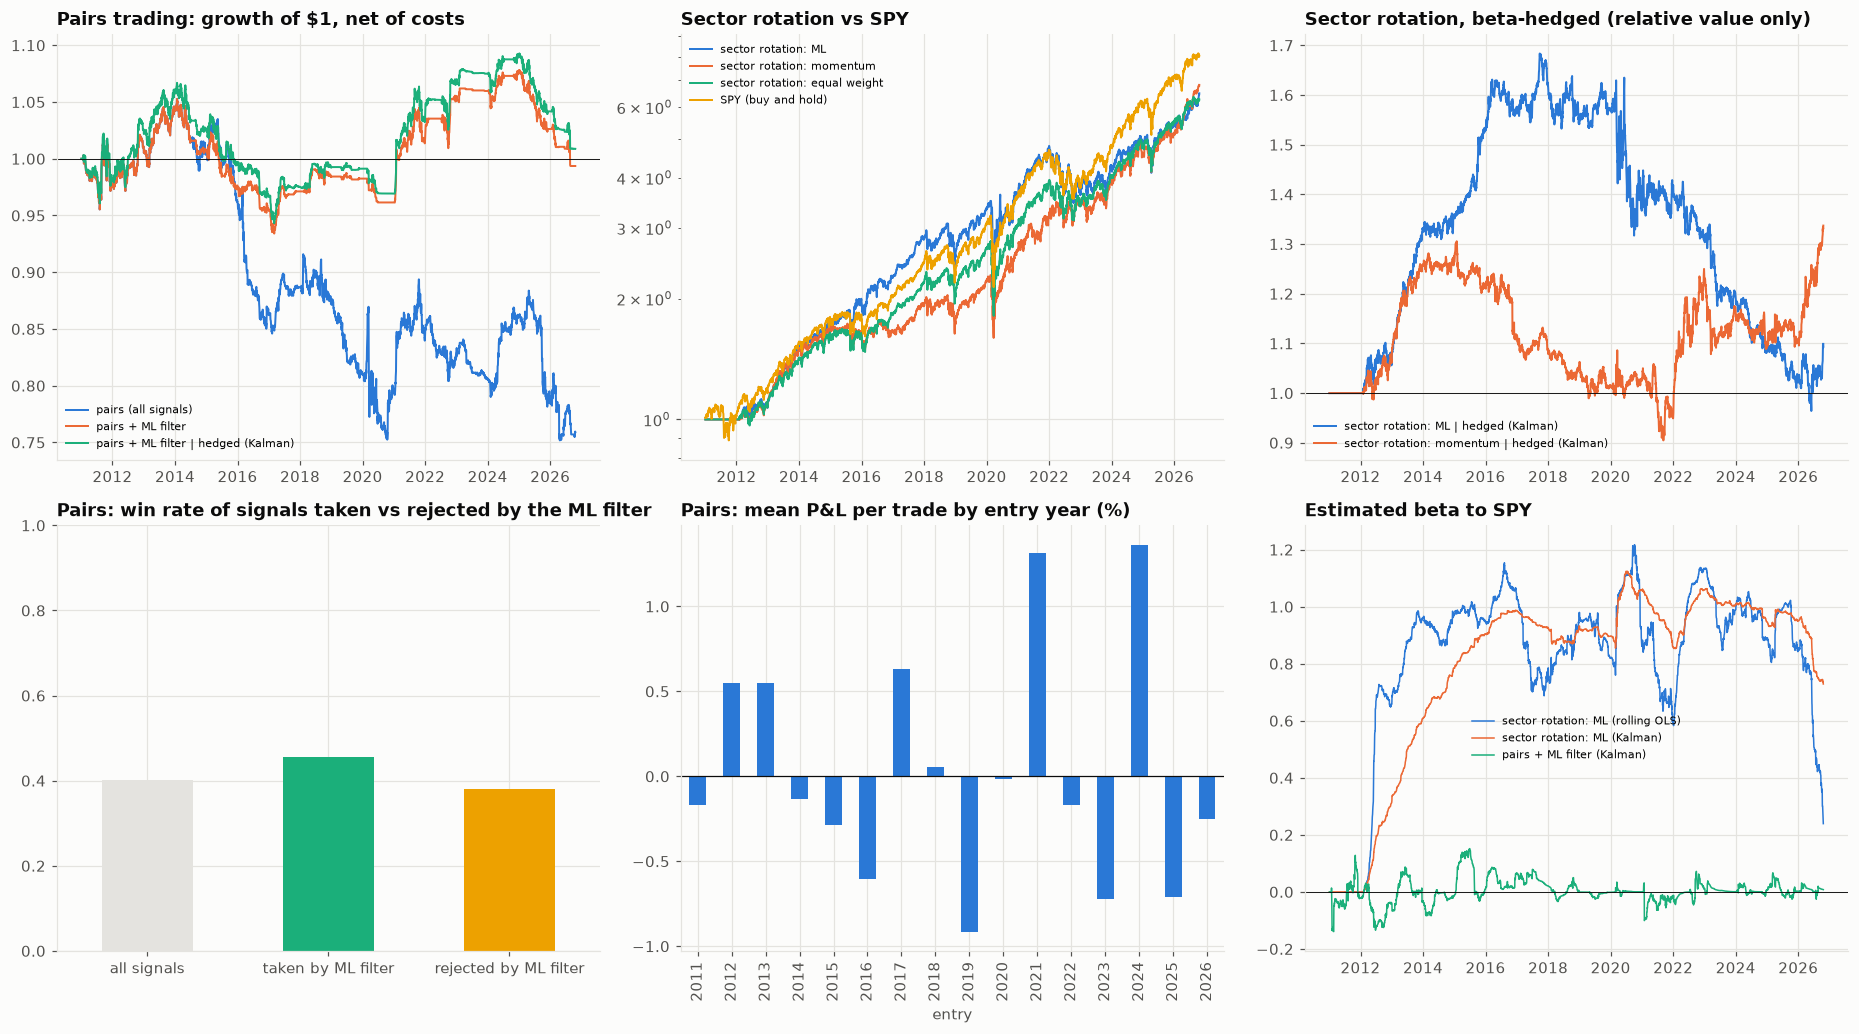

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
a = ax[0, 0]
for k, c in zip(
    [
        "pairs (all signals)",
        "pairs + ML filter",
        "pairs + ML filter | hedged (Kalman)",
    ],
    PALETTE,
):
    a.plot((1 + ALLR[k]).cumprod(), color=c, lw=1.3, label=k)
a.axhline(1, color=INK, lw=0.6)
a.legend(fontsize=7)
a.set_title("Pairs trading: growth of $1, net of costs")
a = ax[0, 1]
for k, c in zip(
    [
        "sector rotation: ML",
        "sector rotation: momentum",
        "sector rotation: equal weight",
        "SPY (buy and hold)",
    ],
    PALETTE,
):
    a.plot((1 + ALLR[k]).cumprod(), color=c, lw=1.3, label=k)
a.set_yscale("log")
a.legend(fontsize=7)
a.set_title("Sector rotation vs SPY")
a = ax[0, 2]
for k, c in zip(
    [
        "sector rotation: ML | hedged (Kalman)",
        "sector rotation: momentum | hedged (Kalman)",
    ],
    PALETTE,
):
    a.plot((1 + ALLR[k]).cumprod(), color=c, lw=1.3, label=k)
a.axhline(1, color=INK, lw=0.6)
a.legend(fontsize=7)
a.set_title("Sector rotation, beta-hedged (relative value only)")
a = ax[1, 0]
FILT["win rate"].plot.bar(ax=a, color=[GRID, PALETTE[2], PALETTE[3]])
a.tick_params(axis="x", rotation=0)
a.set_ylim(0, 1)
a.set_title("Pairs: win rate of signals taken vs rejected by the ML filter")
a = ax[1, 1]
by_year["mean_pnl_pct"].plot.bar(ax=a, color=PALETTE[0])
a.axhline(0, color=INK, lw=0.8)
a.set_title("Pairs: mean P&L per trade by entry year (%)")
a = ax[1, 2]
for (name, m), c in zip(
    [
        ("sector rotation: ML", "rolling OLS"),
        ("sector rotation: ML", "Kalman"),
        ("pairs + ML filter", "Kalman"),
    ],
    PALETTE,
):
    a.plot(BETAS[(name, m)], color=c, lw=1, label=f"{name} ({m})")
a.axhline(0, color=INK, lw=0.6)
a.legend(fontsize=7)
a.set_title("Estimated beta to SPY")
fig.tight_layout()
save_fig(fig, "01_backtests_pairs_rotation_hedging")
plt.show()

In [11]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Growth of $1 (net)",
        "Sharpe ratio by strategy",
        "Pairs: trades by exit reason",
        "Sector rotation: monthly rank IC (12-month rolling)",
    ),
)
for k, c in zip(
    [
        "pairs (all signals)",
        "pairs + ML filter",
        "sector rotation: ML",
        "sector rotation: momentum",
        "SPY (buy and hold)",
    ],
    PALETTE,
):
    dash.add_trace(
        go.Scatter(
            x=ALLR[k].index,
            y=(1 + ALLR[k]).cumprod(),
            name=k,
            line=dict(color=c),
        ),
        1,
        1,
    )
dash.add_trace(
    go.Bar(
        x=PERF.index,
        y=PERF["Sharpe"],
        marker_color=PALETTE[0],
        showlegend=False,
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=trade_tab.index,
        y=trade_tab["trades"],
        marker_color=PALETTE[3],
        showlegend=False,
    ),
    2,
    1,
)
dash.add_trace(
    go.Scatter(
        x=ic.index,
        y=ic.rolling(12).mean(),
        line=dict(color=PALETTE[2]),
        name="rolling IC",
    ),
    2,
    2,
)
dash.update_layout(
    height=860,
    width=1400,
    template="simple_white",
    title="Strategy backtests with vectorbt",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 7. Reading the results and limitations

**Pairs trading does not pay after costs, and the ML filter mostly helps by trading less.**
- 261 cointegrated pairs over 32 formation windows produced 755 trades. Only 20% converged; 66% hit the |z| > 4 stop. Cointegration found in one year often breaks in the next, which is the standard finding since Gatev, Goetzmann and Rouwenhorst (2006): pairs profits have shrunk a lot since the 1990s.
- Converged trades earn about +4.4% gross and win 99% of the time, but the stops lose 1.5% each and are three times as frequent.
- All signals together: −1.7% a year, Sharpe −0.32, a 29% drawdown.
- The LightGBM filter keeps 28% of the signals. Kept trades made +0.07% on average, rejected ones −0.17%, so it does separate better trades from worse ones. But the filtered book only reaches break-even (Sharpe about 0), mainly because it avoids losing trades and pays less than half the fees ($69k against $143k on $1mm).

**Sector rotation earns market returns, not alpha.**
- The ML ranking of the nine sector ETFs has a mean monthly rank IC of 0.049 (t = 1.6): weakly positive, not significant.
- Long-only, the ML top three return 12.6% a year (Sharpe 0.78). That is the same as 12-month momentum (13.0%, 0.85), equal weight (12.4%, 0.84) and SPY (14.2%, 0.86). The beta to SPY is 0.85.
- Once the market is hedged out, almost nothing is left: ML 0.6% a year with the Kalman hedge and −0.2% with rolling OLS; momentum +1.9% (Sharpe 0.28).

**Beta hedging works as a risk tool.** Both hedges cut the rotation portfolios' beta from about 0.8 to under 0.06 and their volatility from 15–17% to about 7.5%. The Kalman beta adapts faster and gives slightly better hedged returns than the rolling OLS beta for every rotation strategy.

A hedge cannot create alpha that is not there: the hedged ML and momentum portfolios still had drawdowns of 31–43%, from long stretches when the chosen sectors lagged the index (12–14% for hedged equal weight).

**Limitations.**
- The stock universe is today's large caps, so it carries survivorship bias, which favours mean reversion: firms that diverged and then failed are missing.
- Borrow costs are a flat 1% a year; hard-to-borrow names cost more.
- Trades fill at the close that generates the signal (a common simplification); a one-day delay would hurt the short-horizon pairs signals most.
- The ML filter and rotation model are retrained once a year with fixed hyperparameters; no tuning was done on the test period, which keeps the results honest but probably not optimal.

In [12]:
T.to_csv(OUT_DIR / "pairs_trade_log.csv", index=False)
PAIRS.to_csv(OUT_DIR / "pairs_selected_by_window.csv", index=False)
FILT.to_csv(OUT_DIR / "ml_filter_effect.csv")
PERF.to_csv(OUT_DIR / "strategy_performance.csv")
VBT_STATS.to_csv(OUT_DIR / "vectorbt_portfolio_stats.csv")
pd.DataFrame(ALLR).to_csv(OUT_DIR / "daily_strategy_returns.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_backtests_pairs_rotation_hedging.png, daily_strategy_returns.csv, dashboard.html, dashboard.png, ml_filter_effect.csv, pairs_selected_by_window.csv, pairs_trade_log.csv, strategy_performance.csv, vectorbt_portfolio_stats.csv


## References

### Finance and regulation

- Gatev, E., Goetzmann, W. N., & Rouwenhorst, K. G. (2006). Pairs trading: Performance of a relative-value arbitrage rule. *The Review of Financial Studies, 19*(3), 797–827. https://doi.org/10.1093/rfs/hhj020
- Engle, R. F., & Granger, C. W. J. (1987). Co-integration and error correction: Representation, estimation, and testing. *Econometrica, 55*(2), 251–276. https://doi.org/10.2307/1913236
- Bailey, D. H., Borwein, J. M., López de Prado, M., & Zhu, Q. J. (2014). Pseudo-mathematics and financial charlatanism: The effects of backtest overfitting on out-of-sample performance. *Notices of the American Mathematical Society, 61*(5), 458–471. https://doi.org/10.1090/noti1105
- Moskowitz, T. J., & Grinblatt, M. (1999). Do industries explain momentum? *The Journal of Finance, 54*(4), 1249–1290. https://doi.org/10.1111/0022-1082.00146
- Bailey, D. H., & López de Prado, M. (2014). The deflated Sharpe ratio: Correcting for selection bias, backtest overfitting and non-normality. *The Journal of Portfolio Management, 40*(5), 94–107. https://doi.org/10.3905/jpm.2014.40.5.094

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Kalman, R. E. (1960). A new approach to linear filtering and prediction problems. *Journal of Basic Engineering, 82*(1), 35–45. https://doi.org/10.1115/1.3662552
- Krauss, C., Do, X. A., & Huck, N. (2017). Deep neural networks, gradient-boosted trees, random forests: Statistical arbitrage on the S&P 500. *European Journal of Operational Research, 259*(2), 689–702. https://doi.org/10.1016/j.ejor.2016.10.031